# Education Project: Socioeconomic Factors Associated with ACT Scores | Regression Analysis

This notebook investigates the relationship between socioeconomic factors and school average ACT scores using linear regression. We start with a set of research questions based on our previous exploratory data analysis. 

We will conduct simple linear regression to investigate the relationship between lunch participation and average ACT scores. We then use multiple linear regression to analyze all numerical socio-economic predictors. Additionally, we will use a categorical variable (charter status of school) to analyze relationship to average ACT scores. 

We will finally compare our regressions models using R-squared, Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

## Import Libraries and Dataset

In [1]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

In [2]:
from pathlib import Path

DATA_DIR = Path('../data')

final_dataset_path = DATA_DIR / 'education_final.csv'

df = pd.read_csv(final_dataset_path  , dtype = {'id': object, 'zip_code': object})

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7857 entries, 0 to 7856
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 7857 non-null   object 
 1   rate_unemployment  7857 non-null   float64
 2   percent_college    7857 non-null   float64
 3   percent_married    7857 non-null   float64
 4   median_income      7857 non-null   float64
 5   average_act        7857 non-null   float64
 6   percent_lunch      7857 non-null   float64
 7   year               7857 non-null   str    
 8   state              7857 non-null   str    
 9   zip_code           7857 non-null   object 
 10  school_type        7857 non-null   str    
 11  school_level       7857 non-null   str    
 12  charter            7857 non-null   str    
 13  grade_12_offered   7857 non-null   str    
dtypes: float64(6), object(2), str(6)
memory usage: 1.1+ MB


## Research Questions | Domain Problems
* How is free or reduced price lunch participation (lunch participation) associated with average ACT scores? We saw a strong negative correlation during our exploration.
* Which socioeconomic factors remain statistically significant with ACT scores when all five numerical predictors are considered?
* Is lunch participation (reduced price lunch participation) the strongest predictor of average ACT scores among the five socioeconomic variables?
* Does charter school status remain associated with average ACT scores after adjusting for socioeconomic factors?

## Simple Linear Regression | Single Input (Percent Lunch)
How is free or reduced price lunch participation (lunch participation) associated with average ACT scores?

Create a regression plot between percent lunch and average act scores

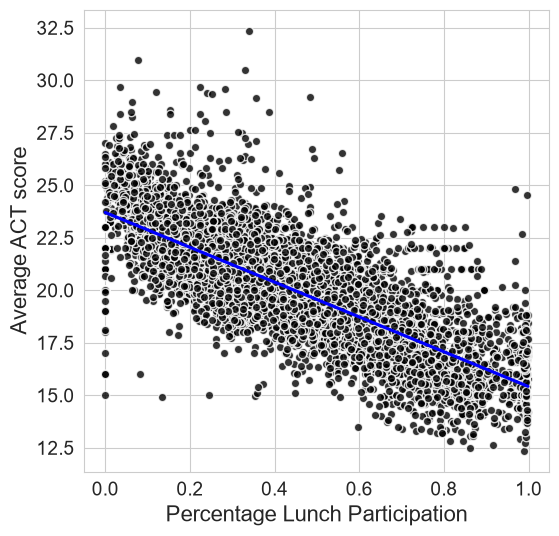

In [4]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'percent_lunch',
           y = 'average_act',
           color = 'blue',
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

# Add axis labels
plt.xlabel('Percentage Lunch Participation', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.savefig(
    '../report/lunch_vs_act.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [5]:
# Fit simple linear regression model using Ordinary Least Squares
model_percent_lunch = smf.ols(formula = 'average_act ~ percent_lunch', data = df).fit()

In [6]:
print(model_percent_lunch.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.605
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                 1.205e+04
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:08:03   Log-Likelihood:                -14757.
No. Observations:                7857   AIC:                         2.952e+04
Df Residuals:                    7855   BIC:                         2.953e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        23.7023      0.036    653.502

* A simple linear regression model was fitted to examine the relationship between lunch participation and average ACT score
* The results indicate a statistically significant negative association.
* With the regression coefficient of -8.2893, a 10 percentage point increase (0.1 increase) in lunch participation is atrributed with ~ 0.83 points lower average ACT scores. (-8.2893 * .10)
* With the calculated R-squared value of .605 the model explains approximately 60.5% of the observed variation in ACT scores.

In [7]:
# y_hat to store predicted value based on regression mo
y_hat = model_percent_lunch.predict()

In [8]:
print(y_hat)

[23.1477428  22.77048988 22.8997705  ... 22.17020381 22.76907569
 22.34534031]


In [9]:
# Mean absolute error
mean_absolute_error(df['average_act'], y_hat)

1.1898350654296694

Plot Residual Error

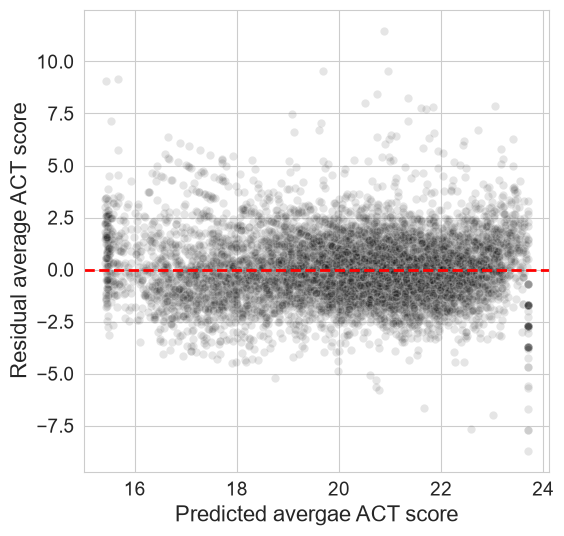

In [10]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model_percent_lunch.resid, 'ko', mec = 'w', alpha=0.1,)
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted avergae ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

* With Mean absolute error of 1.19, on average the simple linear model's predictions were different by 1.19 points.
* Toward the end of the residual plot we see some extreme variations in prediction. Some close to or exeeding 10 points.  

### QQ Plot of Residuals from Simple Linear Model
This will help us find if our model residuals follows a normal distribution.

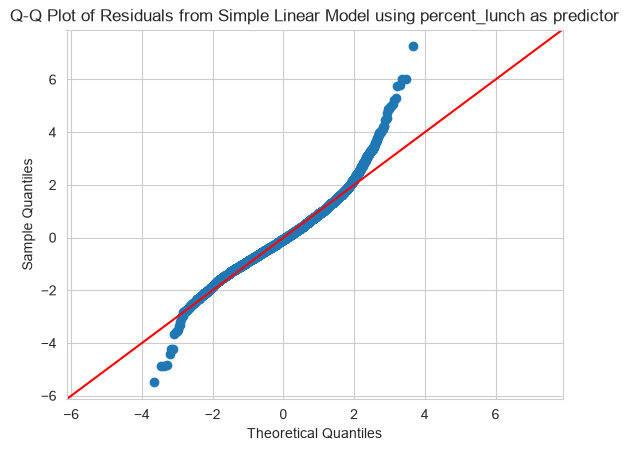

In [11]:
sm.qqplot(
    model_percent_lunch.resid,
    line='45',
    fit=True
)

plt.title('Q-Q Plot of Residuals from Simple Linear Model using percent_lunch as predictor')
plt.show()

* The resuduals are close to the normal line in the middle section
* Extreme results on both tails with lower tail below the normal line and upper tail above the normal line.

### Try quadratic model

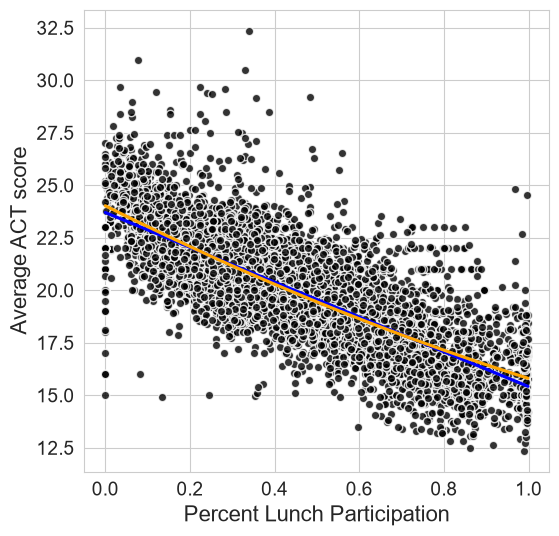

In [12]:
plt.figure(figsize = (6, 6))

sns.regplot(data = df,
           x = 'percent_lunch',
           y = 'average_act',
           color = 'blue',
           ci = False,
           scatter_kws = {'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

sns.regplot(data = df,
           x = 'percent_lunch',
           y = 'average_act',
           order = 2, # compute a quadratic regression line
           color = 'orange',
           ci = False,
           scatter = False)

# Add axis labels
plt.xlabel('Percent Lunch Participation', fontsize = 16)
plt.ylabel('Average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

* The quadratic model does not provide any material imporvement compared to the linear model. 

## Multiple Linear Regression | All Numerical Predictors
Which socioeconomic factors remain statistically significant with ACT scores when all five numerical predictors are considered?

Fit a multiple linear regression model using all five numerical socioeconomic predictors to examine their associations with average ACT scores while holding the other predictors constant.

We will evaluate which predictors are statistically significant and how much variation in average ACT scores the model explains.

In [13]:
model = smf.ols(
    formula = 'average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch ',
    data = df).fit()

In [14]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.618
Model:                            OLS   Adj. R-squared:                  0.618
Method:                 Least Squares   F-statistic:                     2544.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:08:06   Log-Likelihood:                -14625.
No. Observations:                7857   AIC:                         2.926e+04
Df Residuals:                    7851   BIC:                         2.930e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6968      0.13

* Percent Married and median income are both not significant with 5% significance threshold.
* Unemployment rate, percent college and percent lunch are statistically significant to predict average ACT scores.
* With the R-squared value of .618 the model explainded about 61.8% of variation in observed average ACT scores.

In [15]:
y_hat = model.predict()

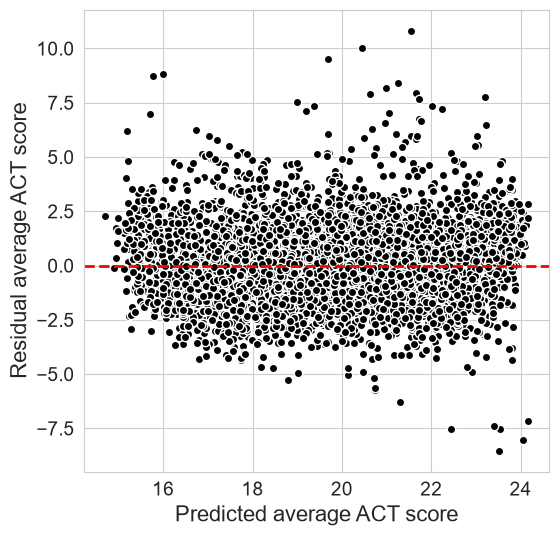

In [16]:
plt.figure(figsize = (6, 6))

plt.plot(y_hat, model.resid, 'ko', mec = 'w')
plt.axhline(0, color = 'r', linestyle = 'dashed', lw = 2)

# Add axis labels
plt.xlabel('Predicted average ACT score', fontsize = 16)
plt.ylabel('Residual average ACT score', fontsize = 16)

# Increase the fontsize of the tick labels
plt.tick_params(labelsize = 14)

plt.show()

In [17]:
mean_absolute_error(df['average_act'], y_hat)

1.1667304906063882

* The residual plot shows errors are distributed around zero.
* With Mean absolute error of 1.17, on average the multiple linear model's predictions were different by 1.17 points.

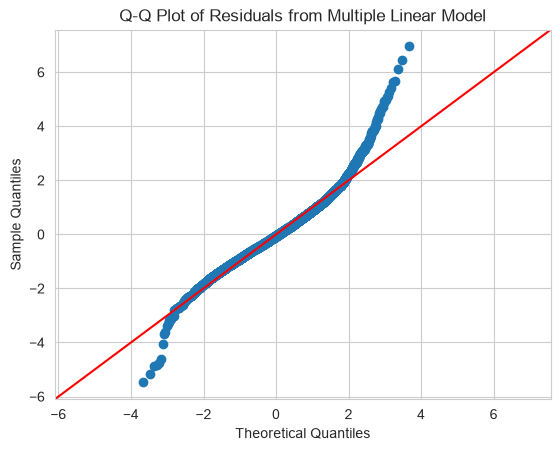

In [18]:
sm.qqplot(model.resid,line='45', fit=True)

plt.title('Q-Q Plot of Residuals from Multiple Linear Model')
plt.show()

* The QQ plot indicates that the residuals follow normal distribution near the center (similar to simple linear model).
* The residual also deviate in both tails with heavier deviation on the upper end.

## Predictor Importance
Is lunch participation (reduced price lunch participation) the strongest predictor of average ACT scores among the five socioeconomic variables?

In [19]:
# Save numerical predictors in a seperate list
numerical_predictors = ['rate_unemployment', 'percent_college', 'percent_married','median_income', 'percent_lunch']

In [20]:
# Create a new list which is going to hold normalized value of numerical predictors
scaled_columns = [var + '_normalized' for var in numerical_predictors]
print(scaled_columns)

['rate_unemployment_normalized', 'percent_college_normalized', 'percent_married_normalized', 'median_income_normalized', 'percent_lunch_normalized']


In [21]:
# Using StandardScaler() to normalize numerical predictors.
scaler = StandardScaler().fit(df[numerical_predictors])

In [22]:
df[scaled_columns] = scaler.transform(df[numerical_predictors])

In [23]:
df[scaled_columns].agg(['mean', 'std']).round(3)

,rate_unemployment_normalized,percent_college_normalized,percent_married_normalized,median_income_normalized,percent_lunch_normalized
mean,0.0,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


Fit a multiple linear regression model using all five normalized numerical socioeconomic predictors to examine their associations with average ACT scores while holding the other predictors constant.

In [24]:
model_normalized = smf.ols(
    formula = 'average_act ~ rate_unemployment_normalized + percent_college_normalized + percent_married_normalized + median_income_normalized + percent_lunch_normalized',
    data = df).fit()

In [25]:
print(model_normalized.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.618
Model:                            OLS   Adj. R-squared:                  0.618
Method:                 Least Squares   F-statistic:                     2544.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:08:06   Log-Likelihood:                -14625.
No. Observations:                7857   AIC:                         2.926e+04
Df Residuals:                    7851   BIC:                         2.930e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

* After normalizing all numerical predictors, we did not deviate from our original r squared of .618.
* With the standardized coefficient of -1.79, Percent lunch had the strongest relation with average act score. The association is negative such that, considering all other predictors to be constant, 1 standard deviation increase in lunch participation is associated with reduction in predicted act score by 1.79 points.
* Percent Colleget had the second-largest absolute standardized coefficient with 0.2822 and was the only predictor with a positive coefficient. A 1 standard deviation increase in percent college is associated with an approximately 0.28 point increase in predicted ACT scores, holding the other predictors constant.

### How our multiple linear model performs without the strongest predictor


In [26]:
model_minus_percent_lunch = smf.ols(
    formula = 'average_act ~ rate_unemployment_normalized + percent_college_normalized + percent_married_normalized + median_income_normalized',
    data = df).fit()

In [27]:
print(model_minus_percent_lunch.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.295
Model:                            OLS   Adj. R-squared:                  0.295
Method:                 Least Squares   F-statistic:                     822.4
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:08:06   Log-Likelihood:                -17035.
No. Observations:                7857   AIC:                         3.408e+04
Df Residuals:                    7852   BIC:                         3.411e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

* The full model including percent lunch explained approximately 61.8% of observed variation in average ACT scores.
* After removing percent lunch participation, R-squared  decreased to 0.295, meaning only 29.5% of oberved variation in average ACT scores were explained.
* Median income and percent married are also statistically significant with the reduced model.
* In summary, lunch participation is one of the most important predictors of average act score. 

## Categorical Analysis | Charter Status
Does charter school status remain associated with average ACT scores after adjusting for socioeconomic factors?

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7857 entries, 0 to 7856
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id                            7857 non-null   object 
 1   rate_unemployment             7857 non-null   float64
 2   percent_college               7857 non-null   float64
 3   percent_married               7857 non-null   float64
 4   median_income                 7857 non-null   float64
 5   average_act                   7857 non-null   float64
 6   percent_lunch                 7857 non-null   float64
 7   year                          7857 non-null   str    
 8   state                         7857 non-null   str    
 9   zip_code                      7857 non-null   object 
 10  school_type                   7857 non-null   str    
 11  school_level                  7857 non-null   str    
 12  charter                       7857 non-null   str    
 13  grade_12_offer

In [29]:
df_charter = df[
    df['charter'].isin(['Yes', 'No'])
].copy()

df_charter['charter_bool'] = (
    df_charter['charter'] == 'Yes'
).astype(int)

df_charter['charter_bool'].value_counts()

charter_bool
0    7296
1     345
Name: count, dtype: int64

In [30]:
model_charter = smf.ols(
    formula='average_act ~ charter_bool',
    data=df_charter
).fit()

print(model_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.010
Model:                            OLS   Adj. R-squared:                  0.009
Method:                 Least Squares   F-statistic:                     73.70
Date:                Wed, 21 Oct 2026   Prob (F-statistic):           1.09e-17
Time:                        19:08:07   Log-Likelihood:                -17908.
No. Observations:                7641   AIC:                         3.582e+04
Df Residuals:                    7639   BIC:                         3.583e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       20.3210      0.030    688.396   

* A simple linear regression model was fitted using charter school status as a binary indicator.
* Charter status is statistically significantly associated with the act score. Coefficient of -1.19 and p value of less than significance level (0.05).
* However with the r squared value of .01 only approximately 1% of the observed variation in observed ACT score was explained by the model.

### Custom Model
We will include the Charter status and numerical predictors except median income and percent married which had the smallest coefficients and were not statistically significant in multiple regression model.

In [31]:
model_custom = smf.ols(
    formula='''
        average_act ~
        rate_unemployment +
        percent_college +
        percent_lunch +
        charter_bool
    ''',
    data=df_charter
).fit()

print(model_custom.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.618
Model:                            OLS   Adj. R-squared:                  0.618
Method:                 Least Squares   F-statistic:                     3086.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:08:07   Log-Likelihood:                -14270.
No. Observations:                7641   AIC:                         2.855e+04
Df Residuals:                    7636   BIC:                         2.858e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            22.6665      0.10

* After adjusting for unemployment rate, college attainement, and lunch participation, the charter school coefficient decreased from −1.1926 to −0.1437 and was no longer statistically significant at the 5% level with p value equal to 0.100.
* After adding charter school status increased R-squared from approximately 0.617679 to 0.617814. The increase of approximately 0.000136, which represents a negligible improvement.

In [32]:
model_without_charter = smf.ols(
    'average_act ~ rate_unemployment + percent_college + percent_lunch',
    data=df_charter
).fit()

print("Without charter:", model_without_charter.rsquared)
print("With charter:", model_custom.rsquared)

print(
    "Change in R²:",
    model_custom.rsquared - model_without_charter.rsquared
)

Without charter: 0.6176788770262814
With charter: 0.6178143845712185
Change in R²: 0.00013550754493707462


* We compared two multiple linear regression models fitted to the same 7,641 schools, with and without charter status.
* Adding charter status increased R squared value from 0.617679 to 0.617814, an improvement of approximately 0.000136 (0.014 % points) which is  negligible increase in explained variation.
* These findings suggest that charter status provides little additional explanatory information about average ACT scores.

## Comparing models
We will use the df_charter dataset to compare:
* Simple Linear Regression using Percent lunch only (M1)
* Multiple Linear Regression using all five numerical predictors (M2)
* Multiple Linear Regression using three numerical predictors (M3)
* Mulitple Linear Regression using three numerical and one categorical Predictor (M4)

In [33]:
# M1: Simple regression
m1 = smf.ols(
    'average_act ~ percent_lunch',
    data=df_charter
).fit()

# M2: Full socioeconomic model
m2 = smf.ols(
    '''average_act ~ rate_unemployment + percent_college
       + percent_married + median_income + percent_lunch''',
    data=df_charter
).fit()

# M3: Reduced socioeconomic model
m3 = model_without_charter

# M4: Reduced model + charter status
m4 = model_custom

In [34]:
models = {
    'M1: Lunch Only': m1,
    'M2: Five Predictors': m2,
    'M3: Three Predictors': m3,
    'M4: Three + Charter': m4
}

comparison = pd.DataFrame({
    name: {
        'Number of Predictors': int(model.df_model),
        'R_squared': model.rsquared,
        'Adjusted_R2': model.rsquared_adj,
        'MAE': mean_absolute_error(
            model.model.endog,
            model.fittedvalues
        ),
        'RMSE': np.sqrt(
            mean_squared_error(
                model.model.endog,
                model.fittedvalues
            )
        )
    }
    for name, model in models.items()
})

comparison.round(4).T

,Number of Predictors,R_squared,Adjusted_R2,MAE,RMSE
M1: Lunch Only,1.0,0.6049,0.6048,1.1968,1.5924
M2: Five Predictors,5.0,0.6177,0.6175,1.1743,1.5663
M3: Three Predictors,3.0,0.6177,0.6175,1.1746,1.5664
M4: Three + Charter,4.0,0.6178,0.6176,1.1749,1.5661


Summary of comparision
* Percent Lunch (Lunch participation) is the most important predictor.
* Adding additional socioeconomic predictors imporve model performance.
* Using three predictors is nearly the same as using all numerical predictors
* Charter status did not materially impact the explanatory power of the model.
* Considering simplicity and performance, using the M3: Three Predictor model may be preferred. 

## Conclusion

This analysis examined the relationship between socioeconomic factors and school average ACT scores using simple and multiple linear regression.

Free or Reduced lunch participation demonstrated the strongest negative association with average ACT scores among the five socioeconomic predictors. The simple linear regression model explained approximately 60.5% of the observed variation in ACT scores. Additionally, this relationship remained statistically significant after accounting for other socioeconomic factors.

The multiple linear regression analysis identified unemployment rate, college attainment, and lunch participation as statistically significant predictors. Median household income and the percentage of children living in married families were not statistically significant after accounting for the other predictors.

Charter school status was statistically significant in the simple linear regression model but was no longer statistically significant after including three other socioeconomic predictors. Hence, including charter status provided negligible improvement.

After comparing all four models, the reduced three predictor model (M3), consisting of unemployment rate, college attainment, and free or reduced price lunch participation, offered a reasonable balance between model simplicity and model performance. It explained approximately 61.8% of the observed variation in ACT scores, performing nearly identically to the full model using all 5 numerical predictors.

Overall, the findings suggest that socioeconomic characteristics, particularly free or reduced price lunch participation, are strongly associated with average ACT scores.